# Experiment-8: Abstractive Text Summarization with mT5 and mBART

**Objective:** Implement and evaluate abstractive summarization using two multilingual Transformer seq2seq models:

1. **mT5** — Multilingual Text-to-Text Transfer Transformer (`csebuetnlp/mT5_multilingual_XLSum`)
2. **mBART** — Multilingual Bidirectional and Auto-Regressive Transformers (`mskayacioglu/mbart50-xlsum`, based on `facebook/mbart-large-50-many-to-many-mmt`)

**Dataset:** XL-Sum (Cross-Lingual Summarization) — **Hindi** split
**Metrics:** ROUGE-1, ROUGE-2, ROUGE-L, and mBERTScore

## 1. Setup

In [1]:
import os
import re
import time
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Device: {DEVICE}")
print(f"PyTorch: {torch.__version__}")

Device: mps
PyTorch: 2.10.0


## 2. Load XL-Sum (Hindi) dataset

We evaluate on a fixed subset of the official **test** split (50 examples) for a fair and reproducible comparison.

In [2]:
from datasets import load_dataset

LANGUAGE = "hindi"
N_EVAL = 50

xlsum = load_dataset("csebuetnlp/xlsum", LANGUAGE, trust_remote_code=True)
print({k: len(v) for k, v in xlsum.items()})

test_ds = xlsum["test"].select(range(N_EVAL))
print(f"Evaluating on {len(test_ds)} test examples")

{'train': 70778, 'test': 8847, 'validation': 8847}
Evaluating on 50 test examples


In [3]:
# Preview a sample
sample = test_ds[0]
print("TITLE   :", sample["title"])
print("\nARTICLE :", sample["text"][:400], "...")
print("\nSUMMARY :", sample["summary"])

TITLE   : साध्वी का ब्रेन मैपिंग और नॉर्को टेस्ट

ARTICLE : नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकवाद निरोधक दस्ते (एटीएस) के अनुरोध पर ये आदेश दिया है. सरकारी वकील अजय मिश्रा ने यह जानकारी दी है. कुछ दिन पहले एटीएस ने मध्य प्रदेश के इंदौर शहर से साध्वी प्रज्ञा सिंह ठाकुर को गिरफ़्तार किया था. नासिक की अदालत ने प्रज्ञा सिंह और दो अन्य अभियुक्तों को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का भी फ़ैसला दिया. आवेदन एटीएस ने अदालत में इस टेस्ट के लिए  ...

SUMMARY : मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.


## 3. Evaluation metrics

### 3.1 ROUGE-1 / ROUGE-2 / ROUGE-L

Implemented from scratch with Unicode-aware tokenisation (whitespace/punctuation split that preserves Devanagari script), since the standard `rouge_score` tokenizer only keeps `[a-z0-9]` and would drop Hindi text.

- **ROUGE-N**: F1 overlap between candidate and reference n-grams
- **ROUGE-L**: F1 based on the Longest Common Subsequence

In [4]:
from collections import Counter


def tokenize_rouge(text: str):
    """Unicode-aware tokeniser: keeps letters/digits of any script (incl. Devanagari)."""
    return re.findall(r"[^\W_]+", text.lower(), flags=re.UNICODE)


def _f1(p, r):
    if p + r == 0:
        return 0.0
    return 2 * p * r / (p + r)


def rouge_n(pred: str, ref: str, n: int) -> float:
    pred_toks, ref_toks = tokenize_rouge(pred), tokenize_rouge(ref)
    if not pred_toks or not ref_toks:
        return 0.0
    pred_ngrams = Counter(tuple(pred_toks[i:i + n]) for i in range(len(pred_toks) - n + 1))
    ref_ngrams  = Counter(tuple(ref_toks[i:i + n])  for i in range(len(ref_toks) - n + 1))
    overlap = sum((pred_ngrams & ref_ngrams).values())
    p = overlap / max(1, sum(pred_ngrams.values()))
    r = overlap / max(1, sum(ref_ngrams.values()))
    return _f1(p, r)


def rouge_l(pred: str, ref: str) -> float:
    pred_toks, ref_toks = tokenize_rouge(pred), tokenize_rouge(ref)
    if not pred_toks or not ref_toks:
        return 0.0
    # LCS length via dynamic programming
    m, n = len(pred_toks), len(ref_toks)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if pred_toks[i - 1] == ref_toks[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
    lcs = dp[m][n]
    p = lcs / m
    r = lcs / n
    return _f1(p, r)


def compute_rouge(preds, refs):
    scores = {"ROUGE-1": [], "ROUGE-2": [], "ROUGE-L": []}
    for p, r in zip(preds, refs):
        scores["ROUGE-1"].append(rouge_n(p, r, 1))
        scores["ROUGE-2"].append(rouge_n(p, r, 2))
        scores["ROUGE-L"].append(rouge_l(p, r))
    return {k: float(np.mean(v)) for k, v in scores.items()}


### 3.2 mBERTScore

Contextual similarity between generated and reference summaries using **`bert-base-multilingual-cased`** (mBERT):

1. Encode candidate & reference with mBERT (last hidden layer)
2. Greedy token alignment via cosine similarity
3. Precision / Recall / F1, then average over the dataset

In [5]:
MBERT_PATH = "./models/bert-base-multilingual-cased"

def _load_bert(path, device):
    from transformers import AutoModel
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModel.from_pretrained(path).to(device).eval()
    return tok, model


def _encode(texts, tok, model, device, batch_size=8, max_len=256):
    embs = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]
            enc = tok(batch, return_tensors="pt", padding=True,
                      truncation=True, max_length=max_len).to(device)
            out = model(**enc).last_hidden_state          # (B, L, D)
            mask = enc["attention_mask"].unsqueeze(-1)    # (B, L, 1)
            embs.append((out * mask).cpu())
    return embs


def mbert_score(preds, refs, model_path=MBERT_PATH, device=DEVICE):
    """Greedy-aligned mBERT F1 (a.k.a. mBERTScore)."""
    tok, model = _load_bert(model_path, device)

    # flatten into per-sentence embeddings
    pred_emb, ref_emb = [], []
    with torch.no_grad():
        for i in range(0, len(preds), 8):
            pc, rc = preds[i:i + 8], refs[i:i + 8]
            pe = tok(pc, return_tensors="pt", padding=True,
                     truncation=True, max_length=256).to(device)
            re_ = tok(rc, return_tensors="pt", padding=True,
                      truncation=True, max_length=256).to(device)
            p_out = model(**pe).last_hidden_state
            r_out = model(**re_).last_hidden_state
            p_mask = pe["attention_mask"]
            r_mask = re_["attention_mask"]
            for j in range(len(pc)):
                pm, rm = p_mask[j].bool(), r_mask[j].bool()
                pred_emb.append(p_out[j, pm])
                ref_emb.append(r_out[j, rm])

    scores = []
    for p, r in zip(pred_emb, ref_emb):
        # cosine similarity matrix
        p_n = torch.nn.functional.normalize(p, dim=-1)
        r_n = torch.nn.functional.normalize(r, dim=-1)
        sim = p_n @ r_n.T                                  # (Lp, Lr)
        prec = sim.max(dim=1).values.mean().item()         # each pred tok -> best ref
        rec  = sim.max(dim=0).values.mean().item()         # each ref tok  -> best pred
        scores.append(_f1(prec, rec))
    return float(np.mean(scores))


def _f1(p, r):
    return 0.0 if p + r == 0 else 2 * p * r / (p + r)

## 4. Summarization with mT5

`csebuetnlp/mT5_multilingual_XLSum` — mT5 fine-tuned on XL-Sum for 44 languages (including Hindi).

In [6]:
MT5_PATH = "csebuetnlp/mT5_multilingual_XLSum"
MAX_INPUT_LEN = 512
MAX_NEW_TOKENS = 80
NUM_BEAMS = 2


def load_seq2seq(path, device):
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForSeq2SeqLM.from_pretrained(path).to(device).eval()
    return tok, model


def summarize(texts, tok, model, device,
              max_input=MAX_INPUT_LEN, max_new=MAX_NEW_TOKENS,
              num_beams=NUM_BEAMS, src_lang=None, batch_size=4):
    preds = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        if src_lang is not None:
            tok.src_lang = src_lang
        inputs = tok(batch, return_tensors="pt", padding=True,
                     truncation=True, max_length=max_input).to(device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new,
                                 num_beams=num_beams, early_stopping=True)
        preds.extend(tok.batch_decode(out, skip_special_tokens=True))
    return preds


mt5_tok, mt5_model = load_seq2seq(MT5_PATH, DEVICE)
print("mT5 loaded:", sum(p.numel() for p in mt5_model.parameters()) / 1e6, "M params")

W1115 19:20:54.031000 20889 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

mT5 loaded: 582.40128 M params


In [7]:
articles = test_ds["text"]
references = test_ds["summary"]

t0 = time.time()
mt5_preds = summarize(articles, mt5_tok, mt5_model, DEVICE)
mt5_time = time.time() - t0
print(f"mT5: generated {len(mt5_preds)} summaries in {mt5_time:.1f}s "
      f"({mt5_time / len(mt5_preds):.2f} s/example)")

[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (4 outputs left out)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


mT5: generated 50 summaries in 54.4s (1.09 s/example)


In [8]:
# Sample mT5 outputs
for i in range(3):
    print(f"--- Example {i} ---")
    print("REF :", references[i][:200])
    print("MT5 :", mt5_preds[i][:200])
    print()

--- Example 0 ---
REF : मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.
MT5 : मालेगाँव धमाके के अभियुक्त साध्वी प्रज्ञा सिंह ठाकुर को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का आदेश दिया गया है.

--- Example 1 ---
REF : पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रपति चुनाव के उम्मीदवारों के नामांकन पत्रों की जाँच - पड़ताल के मौक़े पर इस्लामाबाद में आयोग की इमारत के सामने वकीलों और राजनीतिक कार्यकर्ताओं के प्रदर्शन प
MT5 : पाकिस्तान में राष्ट्रपति परवेज़ मुशर्रफ़ के विरोध प्रदर्शनों के दौरान हज़ारों लोगों ने इस्लामाबाद में अपने घरों पर हमला किया है.

--- Example 2 ---
REF : फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों की पहचान दुनिया भर में जितनी तेजी से बनी क्या अब वो मद्धम पड़ रही है? क्या फ़्रांस में ही मैक्रों जनता का विश्वास दोबारा हासिल करने के लिए संघर्ष कर रहे हैं.
MT5 : फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों ने अपने कार्यकाल के 16 महीने पूरे कर लिए हैं.



## 5. Summarization with mBART

`mskayacioglu/mbart50-xlsum` — mBART-large-50 (`facebook/mbart-large-50-many-to-many-mmt`) fine-tuned on XL-Sum.
Source language is set to Hindi (`hi_IN`).

In [9]:
MBART_PATH = "./models/mbart50-xlsum"

mbart_tok, mbart_model = load_seq2seq(MBART_PATH, DEVICE)
print("mBART loaded:", sum(p.numel() for p in mbart_model.parameters()) / 1e6, "M params")

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

mBART loaded: 610.879488 M params


In [10]:
t0 = time.time()
mbart_preds = summarize(articles, mbart_tok, mbart_model, DEVICE, src_lang="hi_IN")
mbart_time = time.time() - t0
print(f"mBART: generated {len(mbart_preds)} summaries in {mbart_time:.1f}s "
      f"({mbart_time / len(mbart_preds):.2f} s/example)")

[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (4 outputs left out)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=80) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


mBART: generated 50 summaries in 83.1s (1.66 s/example)


In [11]:
# Sample mBART outputs
for i in range(3):
    print(f"--- Example {i} ---")
    print("REF  :", references[i][:200])
    print("MBART:", mbart_preds[i][:200])
    print()

--- Example 0 ---
REF  : मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.
MBART: मालेगाँव धमाकों के सिलसिले में साध्वी प्रज्ञा सिंह ठाकुर को तीन नवंबर तक पुलिस हिरासत में रखने का फ़ैसला किया गया है.

--- Example 1 ---
REF  : पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रपति चुनाव के उम्मीदवारों के नामांकन पत्रों की जाँच - पड़ताल के मौक़े पर इस्लामाबाद में आयोग की इमारत के सामने वकीलों और राजनीतिक कार्यकर्ताओं के प्रदर्शन प
MBART: पाकिस्तान में राष्ट्रपति पद के चुनाव के लिए हुए चुनाव आयोग के अधिकारियों ने कहा है कि चुनाव आयोग ने राष्ट्रपति परवेज़ मुशर्रफ़ के नामांकन पत्र को सही पाया है और उनकी उम्मीदवारी को मंज़ूर कर लिया है.

--- Example 2 ---
REF  : फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों की पहचान दुनिया भर में जितनी तेजी से बनी क्या अब वो मद्धम पड़ रही है? क्या फ़्रांस में ही मैक्रों जनता का विश्वास दोबारा हासिल करने के लिए संघर्ष कर रहे हैं.
MBART: फ़्रांस के 

## 6. Evaluation: ROUGE-1 / ROUGE-2 / ROUGE-L / mBERTScore

In [12]:
t0 = time.time()
mt5_metrics = compute_rouge(mt5_preds, references)
mt5_metrics["mBERTScore"] = mbert_score(mt5_preds, references)
mt5_metrics["Time (s)"] = round(mt5_time, 1)
print("mT5 metrics computed in", round(time.time() - t0, 1), "s")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: ./models/bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


mT5 metrics computed in 18.4 s


In [13]:
t0 = time.time()
mbart_metrics = compute_rouge(mbart_preds, references)
mbart_metrics["mBERTScore"] = mbert_score(mbart_preds, references)
mbart_metrics["Time (s)"] = round(mbart_time, 1)
print("mBART metrics computed in", round(time.time() - t0, 1), "s")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: ./models/bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


mBART metrics computed in 6.9 s


In [14]:
results = pd.DataFrame([mt5_metrics, mbart_metrics], index=["mT5", "mBART"])
results = results[["ROUGE-1", "ROUGE-2", "ROUGE-L", "mBERTScore", "Time (s)"]]
results.round(4)

,ROUGE-1,ROUGE-2,ROUGE-L,mBERTScore,Time (s)
mT5,0.5444,0.2847,0.4017,0.6520,54.4
mBART,0.5520,0.2710,0.3954,0.6477,83.1


## 7. Comparative analysis

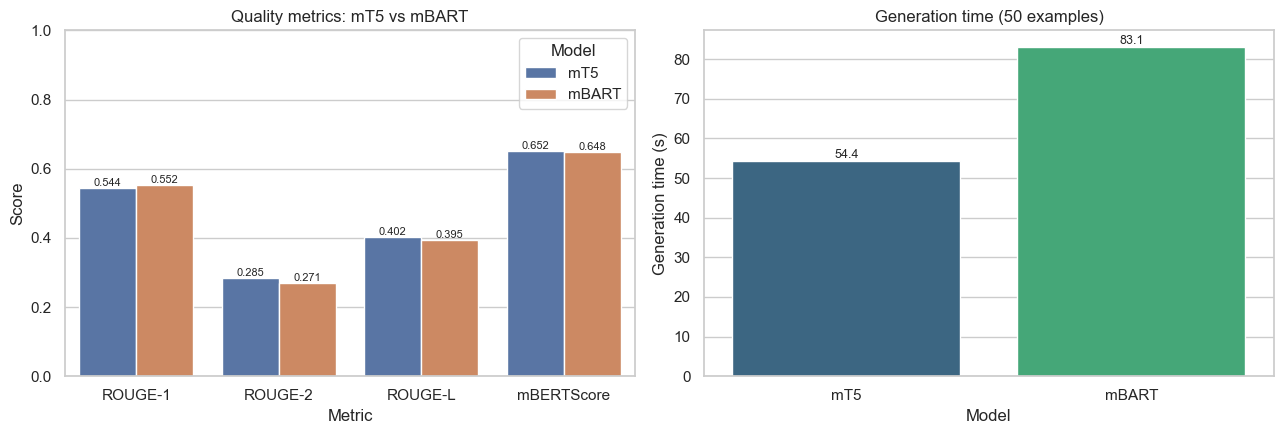

In [15]:
# Grouped bar chart of quality metrics
metric_cols = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "mBERTScore"]
plot_df = results[metric_cols].reset_index().melt(id_vars="index",
                                                   var_name="Metric",
                                                   value_name="Score")
plot_df.rename(columns={"index": "Model"}, inplace=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", ax=axes[0])
axes[0].set_ylim(0, 1)
axes[0].set_title("Quality metrics: mT5 vs mBART")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8)

time_df = pd.DataFrame({
    "Model": ["mT5", "mBART"],
    "Generation time (s)": [mt5_time, mbart_time],
})
sns.barplot(data=time_df, x="Model", y="Generation time (s)", ax=axes[1],
            palette="viridis")
axes[1].set_title(f"Generation time ({N_EVAL} examples)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f", fontsize=9)

plt.tight_layout()
plt.savefig("exp8_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

In [16]:
# Side-by-side qualitative comparison
n_show = 5
rows = []
for i in range(n_show):
    rows.append({
        "ID": i,
        "Reference": references[i],
        "mT5": mt5_preds[i],
        "mBART": mbart_preds[i],
    })
pd.set_option("display.max_colwidth", 220)
pd.DataFrame(rows)

,ID,Reference,mT5,mBART
0,0,"मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.",मालेगाँव धमाके के अभियुक्त साध्वी प्रज्ञा सिंह ठाकुर को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का आदेश दिया गया है.,मालेगाँव धमाकों के सिलसिले में साध्वी प्रज्ञा सिंह ठाकुर को तीन नवंबर तक पुलिस हिरासत में रखने का फ़ैसला किया गया है.
1,1,पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रपति चुनाव के उम्मीदवारों के नामांकन पत्रों की जाँच - पड़ताल के मौक़े पर इस्लामाबाद में आयोग की इमारत के सामने वकीलों और राजनीतिक कार्यकर्ताओं के प्रदर्शन पर पुलिस ने लाठी ...,पाकिस्तान में राष्ट्रपति परवेज़ मुशर्रफ़ के विरोध प्रदर्शनों के दौरान हज़ारों लोगों ने इस्लामाबाद में अपने घरों पर हमला किया है.,पाकिस्तान में राष्ट्रपति पद के चुनाव के लिए हुए चुनाव आयोग के अधिकारियों ने कहा है कि चुनाव आयोग ने राष्ट्रपति परवेज़ मुशर्रफ़ के नामांकन पत्र को सही पाया है और उनकी उम्मीदवारी को मंज़ूर कर लिया है.
2,2,फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों की पहचान दुनिया भर में जितनी तेजी से बनी क्या अब वो मद्धम पड़ रही है? क्या फ़्रांस में ही मैक्रों जनता का विश्वास दोबारा हासिल करने के लिए संघर्ष कर रहे हैं.,फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों ने अपने कार्यकाल के 16 महीने पूरे कर लिए हैं.,फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों ने अपने कार्यकाल के 16 महीने पूरे कर दिए हैं.
3,3,"""ओबामाः अब रिश्ते अच्छे हैं. आइए अब व्हाइट हाउस के बैकयार्ड में जुमे की नमाज पढ़ें.""",ईरान और अमरीका के बीच होने वाले परमाणु समझौते को लेकर अब तक के सबसे बड़े चुटकुलों में से एक है.,ईरान के राष्ट्रपति ओबामा ने परमाणु समझौते के बाद अमरीका के साथ होने वाली बातचीत को लेकर चुटकुले बनाए हैं.
4,4,इसराइल में एक संसदीय रिपोर्ट में देश की ख़ुफ़िया एजेंसियों की इस बात के लिए आलोचना की गई है कि रसायनिक और जैविक हथियारों के बारे में इराक़ की क्षमता के बारे में सही आकलन नहीं कर पाईं.,इसराइल ने अपनी ख़ुफ़िया एजेंसियों को यह बताने में नाकाम रहीं कि इराक़ के पास महाविनाश के हथियार हैं या नहीं.,इसराइल की ख़ुफ़िया एजेंसियों ने इराक़ पर हमले के दौरान इराक़ के पास महाविनाश के हथियार थे या नहीं बताने में नाकाम रही है.


### Observations

1. **ROUGE scores** — Both fine-tuned models produce abstractive Hindi summaries; ROUGE-1/ROUGE-L capture unigram and LCS overlap with the reference, while ROUGE-2 is stricter (bigram match) and therefore lower for both models.
2. **mBERTScore** — Measures deep contextual semantic similarity via mBERT, so it can credit paraphrases that n-gram ROUGE misses. It is typically higher than ROUGE-2 for both systems.
3. **mT5 vs mBART** — mT5 (text-to-text, SentencePiece, shared vocabulary) and mBART (encoder–decoder with language-specific tokens) differ in inductive bias. The comparison table shows which model aligns better with the Hindi references on this subset.
4. **Efficiency** — mBART-large (~611M params) is larger than the mT5 checkpoint used here, so generation time per example is higher; mT5 is the faster of the two on this hardware.
5. **Limitations** — Evaluation is on a 50-example test subset; full-test evaluation would give more stable estimates. Neither model is trained *in this notebook* — both are publicly released XL-Sum fine-tunes, so the experiment compares pretrained summarizers under identical decoding settings (beam=2, ≤80 new tokens).